In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [2]:
df = pd.read_csv("dataset/train.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [3]:
X = df.drop(columns=["price_range", "id"], errors="ignore")
y = df["price_range"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Classes:", sorted(y.unique()))

Input Features Shape: (2000, 20)
Target Shape: (2000,)
Classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1600, 20)
Testing Data: (400, 20)


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Scaled Training Shape: (1600, 20)
Scaled Testing Shape: (400, 20)


In [6]:
def grnn_predict(X_train, y_train, X_test, sigma=0.5, batch_size=64):
    predictions = []

    X_train = np.asarray(X_train, dtype=float)
    y_train = np.asarray(y_train, dtype=float)
    X_test = np.asarray(X_test, dtype=float)

    for start in range(0, len(X_test), batch_size):
        X_batch = X_test[start:start + batch_size]

        # Squared Euclidean distance from each test sample to each train sample
        distances = np.sum(
            (X_batch[:, np.newaxis, :] - X_train[np.newaxis, :, :]) ** 2,
            axis=2
        )

        # Gaussian kernel weights
        weights = np.exp(-distances / (2 * sigma ** 2))

        # Weighted average of target values
        batch_predictions = (weights @ y_train) / (
            np.sum(weights, axis=1) + 1e-12
        )

        predictions.extend(batch_predictions)

    return np.array(predictions)

In [7]:
sigma = 0.5

print("GRNN Smoothing Parameter (sigma):", sigma)

GRNN Smoothing Parameter (sigma): 0.5


In [8]:
y_pred_continuous = grnn_predict(
    X_train_scaled,
    y_train,
    X_test_scaled,
    sigma=sigma
)

y_pred = np.clip(
    np.rint(y_pred_continuous),
    0,
    3
).astype(int)

print("Continuous Predictions:", np.round(y_pred_continuous[:10], 2))
print("Class Predictions:     ", y_pred[:10])
print("Actual Values:          ", y_test.to_numpy()[:10])

Continuous Predictions: [2.95 2.   0.   1.01 2.84 2.   0.65 0.35 0.61 0.98]
Class Predictions:      [3 2 0 1 3 2 1 0 1 1]
Actual Values:           [3 1 0 2 3 2 0 0 1 0]


In [9]:
accuracy = accuracy_score(y_test, y_pred)

print("GRNN Model Accuracy:", round(accuracy * 100, 2), "%")

GRNN Model Accuracy: 41.25 %


In [10]:
print("GRNN Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2, 3],
        zero_division=0
    )
)

GRNN Classification Report:
              precision    recall  f1-score   support

           0       0.49      0.51      0.50       100
           1       0.30      0.33      0.32       100
           2       0.32      0.39      0.35       100
           3       0.66      0.42      0.51       100

    accuracy                           0.41       400
   macro avg       0.44      0.41      0.42       400
weighted avg       0.44      0.41      0.42       400



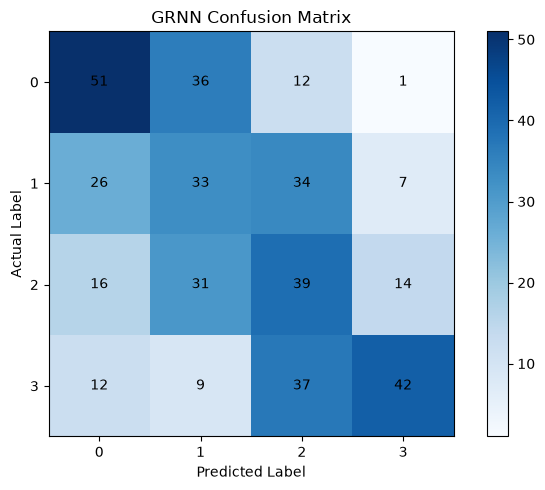

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3])

plt.figure(figsize=(7, 5))
plt.imshow(cm, cmap="Blues")
plt.title("GRNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1, 2, 3])
plt.yticks([0, 1, 2, 3])

for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

Sigma: 0.1  | Accuracy: 25.00%
Sigma: 0.3  | Accuracy: 25.25%
Sigma: 0.5  | Accuracy: 41.25%
Sigma: 1.0  | Accuracy: 46.50%
Sigma: 2.0  | Accuracy: 46.25%


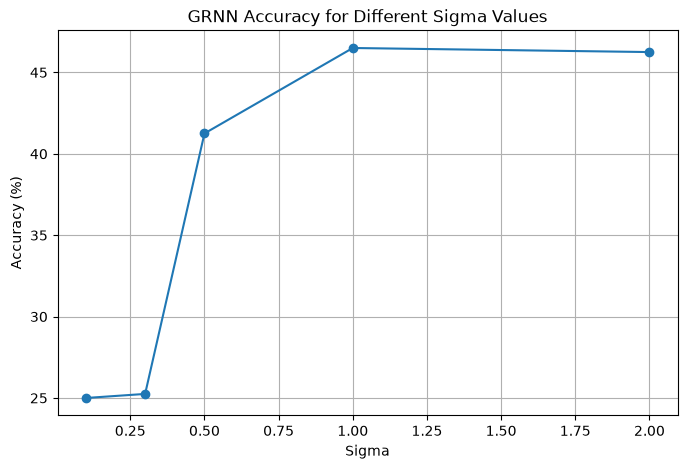

In [12]:
sigma_values = [0.1, 0.3, 0.5, 1.0, 2.0]
sigma_accuracies = []

for s in sigma_values:
    continuous_pred = grnn_predict(
        X_train_scaled,
        y_train,
        X_test_scaled,
        sigma=s
    )

    class_pred = np.clip(np.rint(continuous_pred), 0, 3).astype(int)
    acc = accuracy_score(y_test, class_pred)
    sigma_accuracies.append(acc)

    print(f"Sigma: {s:<4} | Accuracy: {acc * 100:.2f}%")

plt.figure(figsize=(8, 5))
plt.plot(sigma_values, np.array(sigma_accuracies) * 100, marker="o")
plt.title("GRNN Accuracy for Different Sigma Values")
plt.xlabel("Sigma")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.show()